# Brechas de bienestar entre países: ¿en qué dimensiones se separan los países con mayor y menor evaluación de vida?

**Proyecto 2 — Visualización reproducible en Python (Seaborn y Plotly)**

Arnold Santiago Torres Anzola · Juan David Cruz Romero · Daniel Alejandro Cipagauta Palacios

---

### Audiencia
Unidad de análisis comparativo del bienestar de un organismo internacional: el equipo de investigadores y analistas de datos que elabora los diagnósticos de país de sus informes de bienestar y desarrollo. Necesita saber si la brecha de bienestar entre países se concentra en la dimensión económica o si también aparece en dimensiones de salud y socioinstitucionales, para decidir qué indicadores incluir en sus diagnósticos.

### Pregunta analítica
> **¿En qué dimensiones del bienestar —económica, de salud y socioinstitucional— se observan las mayores diferencias entre los países con mayor y menor evaluación de vida en el World Happiness Report 2024?**

Subpregunta: **¿qué países se apartan del patrón de su grupo?**

### Alcance
El análisis es **descriptivo y comparativo**. Las contribuciones del archivo son asociaciones estimadas por el modelo del WHR, no efectos causales; ninguna diferencia observada se interpreta como causa de la evaluación de vida.

### Estructura del Notebook
1. Configuración · 2. Carga e inspección de los datos originales · 3. Diccionario de variables · 4. Preparación · 5. Exploración de las brechas · 6. Visualizaciones estáticas (Seaborn) · 7. Visualizaciones interactivas (Plotly) · 8. Conclusiones, limitaciones y nuevas preguntas

## 1. Configuración

Requisitos: `pip install pandas xlrd matplotlib seaborn plotly` (`xlrd` es necesario porque el archivo oficial está en formato `.xls`).

El Notebook espera la estructura del repositorio: el archivo original en `data/` y los resultados en `resultados/`. En **Google Colab**, quitar el comentario de la primera celda para clonar el repositorio.

In [1]:
# Solo en Google Colab: clonar el repositorio para tener los datos originales
# !git clone https://github.com/danielo2858-spec/proyecto-2.git
# %cd proyecto-2
# !pip install -q xlrd

In [2]:
# 1.1 Librerías
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import plotly
import plotly.graph_objects as go
import plotly.io as pio

print(f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | "
      f"seaborn {sns.__version__} | plotly {plotly.__version__}")

# 1.2 Rutas: la fuente original nunca se modifica; todo lo derivado va a resultados/
RUTA_DATOS = Path("data") / "WHR24_Data_Figure_2.1.xls"
RUTA_RESULTADOS = Path("resultados")
RUTA_RESULTADOS.mkdir(exist_ok=True)

# 1.3 Renderizado de Plotly según el entorno (Colab o Jupyter / VS Code)
try:
    import google.colab  # noqa: F401
    pio.renderers.default = "colab"
except ImportError:
    pio.renderers.default = "notebook_connected+plotly_mimetype"

pandas 3.0.5 | matplotlib 3.11.2 | seaborn 0.13.2 | plotly 7.1.0


In [3]:
# 1.4 Nombres y colores fijos: cada dimensión conserva su color en todos los gráficos
COLUMNAS = {
    "Country name": "pais",
    "Ladder score": "evaluacion_vida",
    "upperwhisker": "ic_superior",
    "lowerwhisker": "ic_inferior",
    "Explained by: Log GDP per capita": "pib",
    "Explained by: Social support": "apoyo_social",
    "Explained by: Healthy life expectancy": "salud",
    "Explained by: Freedom to make life choices": "libertad",
    "Explained by: Generosity": "generosidad",
    "Explained by: Perceptions of corruption": "corrupcion",
    "Dystopia + residual": "distopia_residual",
}
COMPONENTES = ["pib", "salud", "apoyo_social", "libertad", "corrupcion", "generosidad"]
SOCIOINSTITUCIONALES = ["apoyo_social", "libertad", "corrupcion"]

ETIQUETAS = {
    "evaluacion_vida": "Evaluación de vida",
    "pib": "PIB per cápita",
    "salud": "Esperanza de vida saludable",
    "apoyo_social": "Apoyo social",
    "libertad": "Libertad para decidir",
    "corrupcion": "Percepción de corrupción",
    "generosidad": "Generosidad",
    "distopia_residual": "Distopía + residual",
    "socioinstitucional": "Socioinstitucional (apoyo + libertad + corrupción)",
}
DIMENSION = {
    "pib": "Económica", "salud": "Salud", "apoyo_social": "Socioinstitucional",
    "libertad": "Socioinstitucional", "corrupcion": "Socioinstitucional",
    "generosidad": "Referencia", "distopia_residual": "Referencia",
}

# Paleta categórica de referencia en su orden fijo (validada para daltonismo en pares adyacentes);
# Distopía + residual en gris porque es lo que el modelo no asocia con ningún indicador
COLORES_DIM = {
    "pib": "#2a78d6", "salud": "#eb6834", "apoyo_social": "#1baf7a",
    "libertad": "#eda100", "corrupcion": "#e87ba4", "generosidad": "#008300",
    "distopia_residual": "#b5b3ab",
}
# Los cuartiles tienen orden: un solo tono, de claro (Q1, más baja) a oscuro (Q4, más alta)
CUARTILES = ["Q1", "Q2", "Q3", "Q4"]
COLORES_CUARTIL = dict(zip(CUARTILES, ["#86b6ef", "#5598e7", "#256abf", "#104281"]))

# Estilo de Seaborn: fondo claro, rejilla tenue y tinta neutra
sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110,
})

## 2. Carga e inspección de los datos originales

**Fuente obligatoria:** World Happiness Report 2024 — *Data for Figure 2.1* (`WHR24_Data_Figure_2.1.xls`), descargado de https://files.worldhappiness.report/WHR24_Data_Figure_2.1.xls. Se conserva sin modificaciones en `data/`.

In [4]:
# 2.1 Importación del archivo original (se conserva intacto en df_original)
df_original = pd.read_excel(RUTA_DATOS, engine="xlrd")
print(f"Filas: {df_original.shape[0]} | Columnas: {df_original.shape[1]}")
df_original.head()

Filas: 143 | Columnas: 11


,Country name,Ladder score,upperwhisker,lowerwhisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,7.7407,7.814808,7.666591,1.844054,1.572367,0.694793,0.859294,0.141674,0.546158,2.082367
1,Denmark,7.5827,7.665297,7.500103,1.907798,1.520361,0.698944,0.822740,0.203579,0.548413,1.880887
2,Iceland,7.5251,7.617527,7.432673,1.880718,1.616525,0.718345,0.818509,0.258344,0.182473,2.050233
3,Sweden,7.3441,7.421563,7.266637,1.878146,1.500826,0.723871,0.838269,0.221455,0.523795,1.657707
4,Israel,7.3411,7.405165,7.277036,1.802934,1.512793,0.739816,0.641463,0.153205,0.192823,2.298026


In [5]:
# 2.2 Tipos de datos y valores no nulos por columna
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 11 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                143 non-null    str    
 1   Ladder score                                143 non-null    float64
 2   upperwhisker                                143 non-null    float64
 3   lowerwhisker                                143 non-null    float64
 4   Explained by: Log GDP per capita            140 non-null    float64
 5   Explained by: Social support                140 non-null    float64
 6   Explained by: Healthy life expectancy       140 non-null    float64
 7   Explained by: Freedom to make life choices  140 non-null    float64
 8   Explained by: Generosity                    140 non-null    float64
 9   Explained by: Perceptions of corruption     140 non-null    float64
 10  Dystopia + residual      

In [6]:
# 2.3 Valores faltantes: qué países y qué columnas
print(df_original.isna().sum().to_string())
df_original[df_original.isna().any(axis=1)]

Country name                                  0
Ladder score                                  0
upperwhisker                                  0
lowerwhisker                                  0
Explained by: Log GDP per capita              3
Explained by: Social support                  3
Explained by: Healthy life expectancy         3
Explained by: Freedom to make life choices    3
Explained by: Generosity                      3
Explained by: Perceptions of corruption       3
Dystopia + residual                           3


,Country name,Ladder score,upperwhisker,lowerwhisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
61,Bahrain,5.9591,6.152547,5.765653,NaN,NaN,NaN,NaN,NaN,NaN,NaN
87,Tajikistan,5.2807,5.360609,5.200792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
102,State of Palestine,4.8795,5.005937,4.753063,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Lectura de la inspección.** El archivo tiene 143 países y 11 columnas: una de texto (`Country name`) y diez numéricas. Tres países —Bahrain, Tajikistan y State of Palestine— tienen evaluación de vida e intervalo de confianza, pero no tienen las contribuciones por indicador. Se conservan para construir los cuartiles y se excluyen solo de los análisis por dimensión.

## 3. Diccionario de variables

El archivo **no contiene los valores originales de los indicadores** (por ejemplo, el porcentaje de personas con apoyo social), sino la **porción de la evaluación de vida que el modelo del WHR asocia con cada indicador**, medida en puntos de la escalera de Cantril y en relación con *Distopía* (un país hipotético con los valores más bajos observados). Por eso todas las contribuciones están en la misma unidad y se pueden comparar entre sí sin estandarizarlas.

| Columna original | Nombre en el Notebook | Qué contiene | Dimensión |
|---|---|---|---|
| `Country name` | `pais` | Nombre del país | — |
| `Ladder score` | `evaluacion_vida` | Promedio nacional de la escalera de Cantril (0–10), 2021–2023 | Variable de referencia |
| `upperwhisker` / `lowerwhisker` | `ic_superior` / `ic_inferior` | Límites del intervalo de confianza al 95 % | Incertidumbre |
| `Explained by: Log GDP per capita` | `pib` | Puntos asociados con el PIB per cápita (PPA, en logaritmo) | Económica |
| `Explained by: Healthy life expectancy` | `salud` | Puntos asociados con la esperanza de vida saludable al nacer | Salud |
| `Explained by: Social support` | `apoyo_social` | Puntos asociados con tener a quién acudir ante un problema | Socioinstitucional |
| `Explained by: Freedom to make life choices` | `libertad` | Puntos asociados con la satisfacción con la libertad para decidir | Socioinstitucional |
| `Explained by: Perceptions of corruption` | `corrupcion` | Puntos asociados con la percepción de corrupción; un valor mayor indica **menos** corrupción percibida respecto de Distopía | Socioinstitucional |
| `Explained by: Generosity` | `generosidad` | Puntos asociados con donar a causas benéficas, ajustado por PIB | Referencia |
| `Dystopia + residual` | `distopia_residual` | Valor de Distopía más lo que el modelo no asocia con ningún indicador | Referencia |

## 4. Preparación de los datos

Todas las transformaciones se hacen sobre una copia (`df`); `df_original` no se modifica.

1. Renombrar columnas a nombres cortos en español.
2. Verificar que las seis contribuciones más `Dystopia + residual` sumen la evaluación de vida.
3. Construir los **cuartiles de evaluación de vida** con `pd.qcut`. Se usan cuartiles porque salen de la propia variable del archivo (no requieren regiones ni niveles de ingreso externos) y dejan grupos de tamaño similar (~36 países).
4. Crear el indicador derivado **socioinstitucional** = apoyo social + libertad + percepción de corrupción. La suma es válida porque las tres contribuciones están en la misma unidad (puntos de la escalera) y el modelo del WHR es aditivo.
5. Separar los países con contribuciones completas (`df_comp`, 140 países) y pasar a formato largo para Seaborn.

In [7]:
# 4.1 Copia de trabajo con nombres cortos
df = df_original.rename(columns=COLUMNAS).copy()

# 4.2 Verificación: componentes + distopía = evaluación de vida (solo filas completas)
suma = df[COMPONENTES + ["distopia_residual"]].sum(axis=1, min_count=7)
diferencia = (suma - df["evaluacion_vida"]).abs()
print(f"Diferencia máxima entre la suma y la evaluación de vida: {diferencia.max():.5f}")
assert diferencia.max() < 0.001, "Los componentes no suman la evaluación de vida"

# 4.3 Cuartiles de evaluación de vida (Q1 = más baja, Q4 = más alta), con los 143 países
df["cuartil"] = pd.qcut(df["evaluacion_vida"], q=4, labels=CUARTILES)

# 4.4 Indicador derivado: dimensión socioinstitucional
df["socioinstitucional"] = df[SOCIOINSTITUCIONALES].sum(axis=1, min_count=3)

# Resumen de los grupos
(df.groupby("cuartil", observed=True)["evaluacion_vida"]
   .agg(paises="count", minimo="min", maximo="max", media="mean").round(2))

Diferencia máxima entre la suma y la evaluación de vida: 0.00005


,paises,minimo,maximo,media
cuartil,,,,
Q1,36,1.72,4.66,3.91
Q2,36,4.79,5.79,5.26
Q3,35,5.82,6.41,6.07
Q4,36,6.42,7.74,6.88


In [8]:
# 4.5 Casos que requieren atención en la interpretación
df_comp = df.dropna(subset=COMPONENTES).copy()   # 140 países con contribuciones completas
print(f"Países con contribuciones completas: {len(df_comp)}")
print("Excluidos del análisis por dimensión:",
      ", ".join(df.loc[df[COMPONENTES].isna().any(axis=1), "pais"]))
print("\nContribución del PIB igual a 0:")
print(df_comp.loc[df_comp["pib"] == 0, ["pais", "evaluacion_vida", "cuartil", "pib"]].to_string(index=False))
print("\nDistopía + residual negativo:")
print(df_comp.loc[df_comp["distopia_residual"] < 0,
                  ["pais", "evaluacion_vida", "cuartil", "distopia_residual"]].to_string(index=False))

# 4.6 Formato largo para Seaborn y archivo preparado para reproducir o ampliar el análisis
df_largo = df_comp.melt(id_vars=["pais", "cuartil", "evaluacion_vida"], value_vars=COMPONENTES,
                        var_name="componente", value_name="contribucion")
df_largo["etiqueta"] = df_largo["componente"].map(ETIQUETAS)
df.to_csv(RUTA_RESULTADOS / "whr24_preparado.csv", index=False)
print(f"\nArchivo preparado guardado en {RUTA_RESULTADOS / 'whr24_preparado.csv'}")

Países con contribuciones completas: 140
Excluidos del análisis por dimensión: Bahrain, Tajikistan, State of Palestine

Contribución del PIB igual a 0:
     pais  evaluacion_vida cuartil  pib
Venezuela           5.6067      Q2  0.0

Distopía + residual negativo:
   pais  evaluacion_vida cuartil  distopia_residual
Lebanon           2.7065      Q1          -0.072831

Archivo preparado guardado en resultados\whr24_preparado.csv


## 5. Exploración de las brechas

Antes de graficar, se calcula la media de cada contribución en el cuartil más alto (Q4) y en el más bajo (Q1), y la **brecha** entre ambos. Como las contribuciones suman la evaluación de vida, las brechas suman la diferencia total entre los grupos; por eso se reporta también qué porcentaje de esa diferencia corresponde a cada componente.

In [9]:
# 5.1 Medias por cuartil y brecha Q4 − Q1 (países con contribuciones completas)
columnas = COMPONENTES + ["distopia_residual", "evaluacion_vida", "socioinstitucional"]
medias = df_comp.groupby("cuartil", observed=True)[columnas].mean()
brechas = pd.DataFrame({
    "Q1": medias.loc["Q1"], "Q4": medias.loc["Q4"],
    "brecha_Q4_Q1": medias.loc["Q4"] - medias.loc["Q1"],
})
brechas["pct_de_la_brecha_total"] = 100 * brechas["brecha_Q4_Q1"] / brechas.loc["evaluacion_vida", "brecha_Q4_Q1"]
brechas.index = brechas.index.map(ETIQUETAS)
brechas.round(2)

,Q1,Q4,brecha_Q4_Q1,pct_de_la_brecha_total
PIB per cápita,0.92,1.82,0.90,30.26
Esperanza de vida saludable,0.35,0.66,0.32,10.66
Apoyo social,0.74,1.41,0.67,22.45
Libertad para decidir,0.49,0.74,0.25,8.41
Percepción de corrupción,0.12,0.29,0.17,5.86
Generosidad,0.15,0.17,0.02,0.58
Distopía + residual,1.15,1.79,0.65,21.77
Evaluación de vida,3.91,6.88,2.96,100.00
Socioinstitucional (apoyo + libertad + corrupción),1.35,2.44,1.09,36.72


In [10]:
# 5.2 Orden de los componentes según su brecha (se usa en todos los gráficos)
ORDEN = (medias.loc["Q4", COMPONENTES] - medias.loc["Q1", COMPONENTES]).sort_values(ascending=False).index.tolist()
[ETIQUETAS[c] for c in ORDEN]

['PIB per cápita',
 'Apoyo social',
 'Esperanza de vida saludable',
 'Libertad para decidir',
 'Percepción de corrupción',
 'Generosidad']

**Lectura de la tabla.** Entre los países del cuartil más alto (Q4) y los del más bajo (Q1) hay una diferencia media de **2,96 puntos** en la evaluación de vida. De esa diferencia:

- El **PIB per cápita** es el componente individual con mayor brecha: 0,90 puntos (30 % del total).
- El **apoyo social** es el segundo: 0,67 puntos (22 %).
- Sumadas, las tres contribuciones **socioinstitucionales** (apoyo social, libertad y corrupción) acumulan 1,09 puntos (37 %), **más que el PIB**.
- La **salud** aporta 0,32 puntos (11 %) y la **generosidad** casi nada (0,02; 0,6 %).
- **Distopía + residual** concentra 0,65 puntos (22 %): una parte importante de la diferencia entre los grupos no se asocia con ninguno de los seis indicadores del modelo.

Estos son promedios. Los gráficos siguientes muestran si la brecha es consistente dentro de cada grupo y si es clara frente a la incertidumbre.

## 6. Visualizaciones estáticas (Seaborn)

### Gráfico 1. Distribución de la evaluación de vida y cortes de los cuartiles
**Qué necesita examinar el analista:** cómo se reparten los 143 países y dónde quedan los grupos que se van a comparar.
**Por qué este gráfico:** el histograma con curva de densidad es la forma estándar de mostrar la distribución de una variable numérica; las líneas de corte muestran que los grupos salen de los datos y no de una decisión arbitraria.

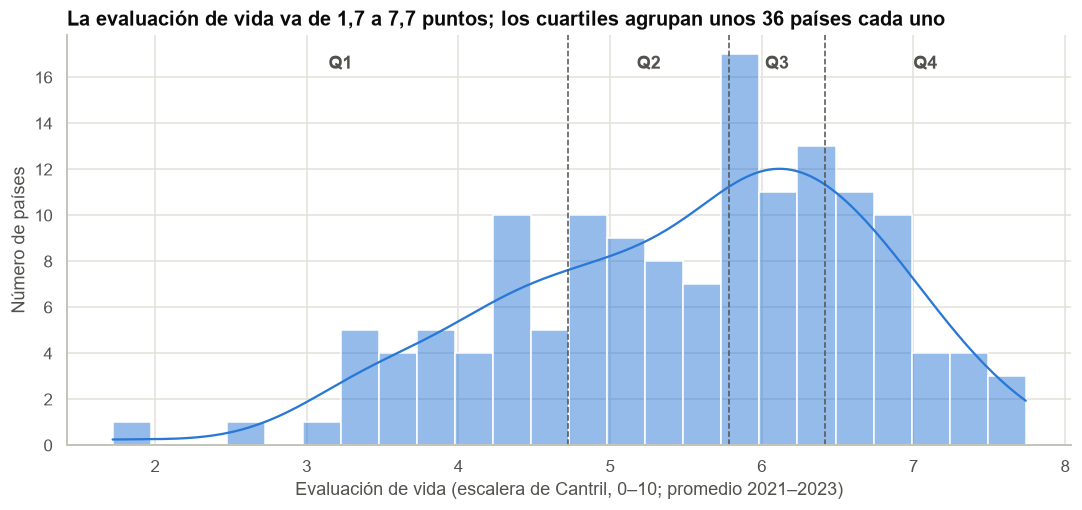

Cortes de los cuartiles: [4.73, 5.79, 6.42]


In [11]:
cortes = df["evaluacion_vida"].quantile([0.25, 0.5, 0.75])
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(data=df, x="evaluacion_vida", bins=24, kde=True, color="#2a78d6",
             edgecolor="white", linewidth=1, ax=ax)

# Cortes de los cuartiles y nombre de cada grupo
for corte in cortes:
    ax.axvline(corte, color="#52514e", linestyle="--", linewidth=1)
limites = [df["evaluacion_vida"].min(), *cortes, df["evaluacion_vida"].max()]
for q, (a, b) in zip(CUARTILES, zip(limites[:-1], limites[1:])):
    ax.text((a + b) / 2, ax.get_ylim()[1] * 0.95, q, ha="center", va="top",
            fontweight="bold", color="#52514e")

ax.set_title("La evaluación de vida va de 1,7 a 7,7 puntos; los cuartiles agrupan unos 36 países cada uno", loc="left")
ax.set_xlabel("Evaluación de vida (escalera de Cantril, 0–10; promedio 2021–2023)")
ax.set_ylabel("Número de países")
sns.despine()
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "g1_distribucion.png", dpi=150)
plt.show()
print("Cortes de los cuartiles:", cortes.round(2).tolist())

**Interpretación.** La distribución es asimétrica: la mayoría de los países se concentra entre 5 y 7 puntos y hay una cola larga hacia valores bajos (Afganistán, 1,72; Líbano, 2,71). Por eso los cuartiles no tienen el mismo ancho: **Q1 abarca casi 3 puntos** (1,72–4,66), mientras que **Q3 abarca apenas 0,6** (5,82–6,41). Dos consecuencias para el análisis:

1. Q1 es el grupo más heterogéneo; su media puede ocultar situaciones muy distintas, lo que justifica revisar países concretos en Plotly.
2. Las diferencias entre los cuartiles del medio son pequeñas, por lo que la comparación entre los extremos (Q1 y Q4) es la que mejor permite ver en qué se separan los países.

### Gráfico 2. Contribución de cada componente según el cuartil
**Qué necesita examinar el analista:** en qué componentes se separan los grupos y cuánta variación hay dentro de cada uno.
**Por qué este gráfico:** los diagramas de caja comparan distribuciones completas, no solo promedios, e incluyen los cuatro cuartiles, lo que muestra si el cambio es gradual o se concentra en los extremos. Los componentes están ordenados de mayor a menor brecha.

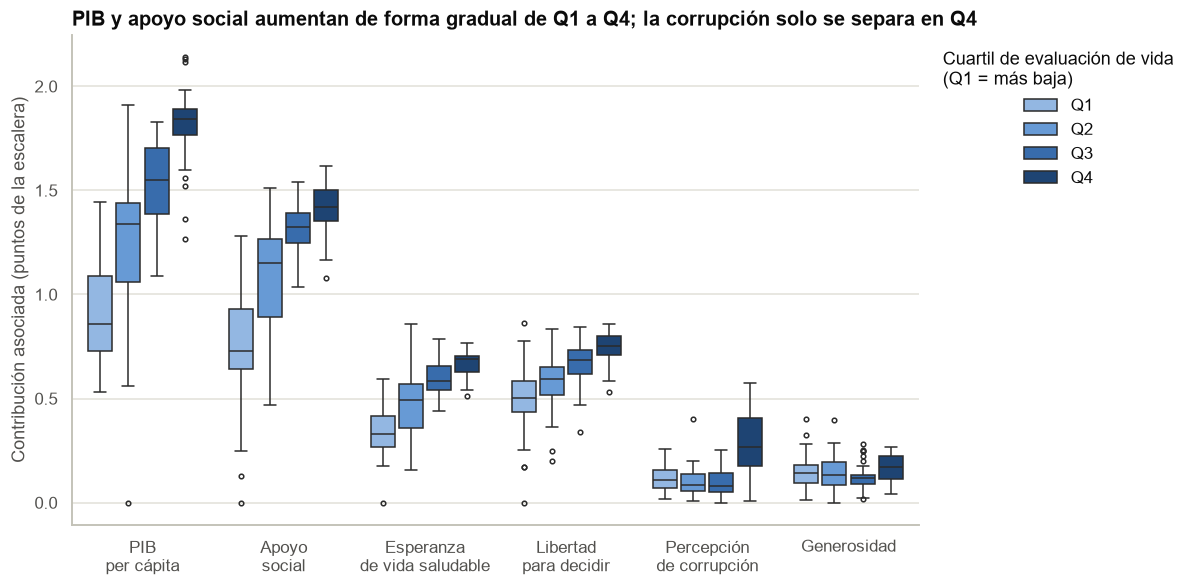

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df_largo, x="etiqueta", y="contribucion", hue="cuartil",
            order=[ETIQUETAS[c] for c in ORDEN], hue_order=CUARTILES, palette=COLORES_CUARTIL,
            linewidth=1, fliersize=3, gap=0.15, ax=ax)
ax.set_title("PIB y apoyo social aumentan de forma gradual de Q1 a Q4; la corrupción solo se separa en Q4", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Contribución asociada (puntos de la escalera)")
ax.set_xticks(ax.get_xticks(), [ETIQUETAS[c].replace(" ", "\n", 1) for c in ORDEN])
ax.legend(title="Cuartil de evaluación de vida\n(Q1 = más baja)", frameon=False,
          bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "g2_boxplots.png", dpi=150)
plt.show()

**Interpretación.**

- **PIB y apoyo social** aumentan de forma gradual de Q1 a Q4 y, entre los extremos, las cajas no se superponen: casi todos los países de Q4 tienen contribuciones mayores que casi todos los de Q1.
- **Salud y libertad** siguen el mismo patrón gradual, pero con brechas más pequeñas.
- **Percepción de corrupción** se comporta distinto: es casi igual en Q1, Q2 y Q3 (alrededor de 0,1) y solo sube en Q4, donde además varía mucho (de 0 a 0,57). Esta dimensión distingue al grupo más alto, pero no ordena a los demás.
- **Generosidad** es prácticamente plana entre cuartiles.
- La dispersión dentro de los grupos es mayor en Q1 y Q2, coherente con lo visto en el gráfico 1. Los valores en 0 son casos particulares: Venezuela en PIB (Q2) y Afganistán en apoyo social y libertad (Q1).

Para la pregunta: las diferencias entre los grupos no se limitan a la dimensión económica; el apoyo social muestra una separación casi tan marcada como el PIB.

### Gráfico 3. Tamaño de la brecha entre Q1 y Q4
**Qué necesita examinar el analista:** cuánto se separan, en promedio, los países de mayor y menor evaluación de vida en cada componente. Es la respuesta directa a la pregunta.
**Por qué este gráfico:** el gráfico de pesas (*dumbbell*) muestra los dos promedios y la distancia entre ellos en la misma escala; a diferencia del gráfico 2, aísla el tamaño de la brecha y lo ordena. Las barras horizontales son intervalos de confianza al 95 % de cada media (bootstrap).

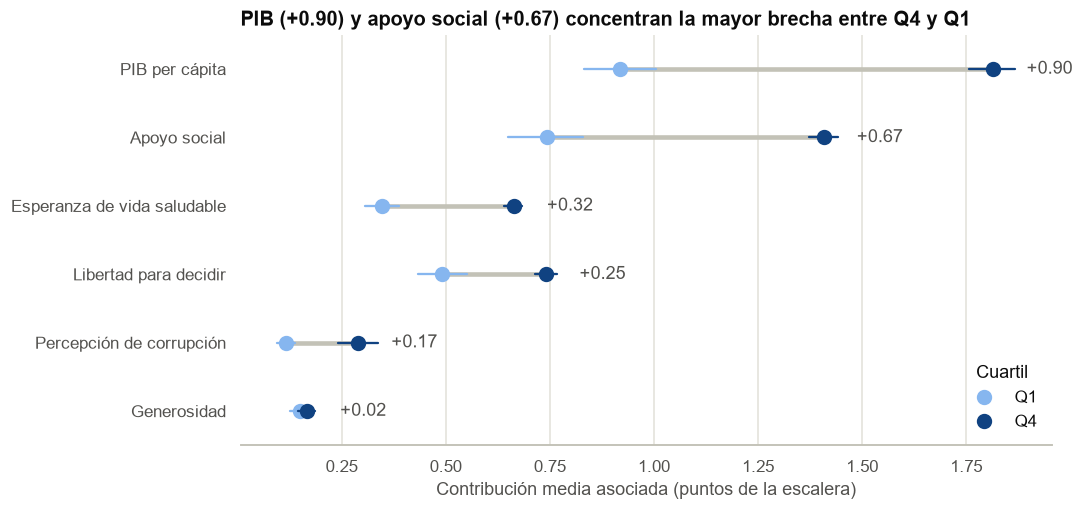

In [13]:
extremos = df_largo[df_largo["cuartil"].isin(["Q1", "Q4"])].copy()
extremos["cuartil"] = extremos["cuartil"].cat.remove_unused_categories()
orden_etiquetas = [ETIQUETAS[c] for c in ORDEN]

fig, ax = plt.subplots(figsize=(10, 4.8))
# Línea gris que une las dos medias de cada componente
for i, c in enumerate(ORDEN):
    ax.plot([medias.loc["Q1", c], medias.loc["Q4", c]], [i, i], color="#c3c2b7", linewidth=3, zorder=1)
sns.pointplot(data=extremos, y="etiqueta", x="contribucion", hue="cuartil", order=orden_etiquetas,
              hue_order=["Q1", "Q4"], palette=COLORES_CUARTIL, linestyle="none", markers="o",
              markersize=8, errorbar=("ci", 95), seed=42, err_kws={"linewidth": 1.5}, ax=ax)
# Valor de la brecha a la derecha de cada fila
for i, c in enumerate(ORDEN):
    brecha = medias.loc["Q4", c] - medias.loc["Q1", c]
    ax.text(medias.loc["Q4", c] + 0.08, i, f"+{brecha:.2f}", va="center", color="#52514e")

b = medias.loc["Q4"] - medias.loc["Q1"]
ax.set_title(f"PIB (+{b['pib']:.2f}) y apoyo social (+{b['apoyo_social']:.2f}) concentran la mayor brecha entre Q4 y Q1",
             loc="left")
ax.set_xlabel("Contribución media asociada (puntos de la escalera)")
ax.set_ylabel("")
ax.legend(title="Cuartil", frameon=False, loc="lower right")
sns.despine(left=True)
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "g3_brechas.png", dpi=150)
plt.show()

**Interpretación.** El gráfico ordena la respuesta a la pregunta: **PIB (+0,90) y apoyo social (+0,67)** concentran las mayores brechas, seguidos por salud (+0,32), libertad (+0,25) y corrupción (+0,17). Los intervalos de confianza de Q1 y Q4 no se superponen en esos cinco componentes, así que las brechas son claras frente a la variación de las medias. En **generosidad** los intervalos se superponen: no hay evidencia de diferencia entre los grupos.

Aunque el PIB es el componente con mayor brecha individual, las tres dimensiones socioinstitucionales juntas (+1,09) la superan. Para la audiencia, esto indica que un diagnóstico centrado solo en indicadores económicos dejaría fuera una parte de la diferencia entre países comparable o mayor.

### Gráfico 4. Correlación entre la evaluación de vida y los componentes
**Qué necesita examinar el analista:** si los componentes varían de forma conjunta. Si lo hacen, las brechas del gráfico 3 no son independientes y no deben leerse como efectos separados.
**Por qué este gráfico:** un mapa de calor resume las 21 correlaciones en una sola vista. Se usa la correlación de Spearman (por rangos) porque varias contribuciones son asimétricas y tienen valores atípicos. La escala divergente usa gris para el cero.

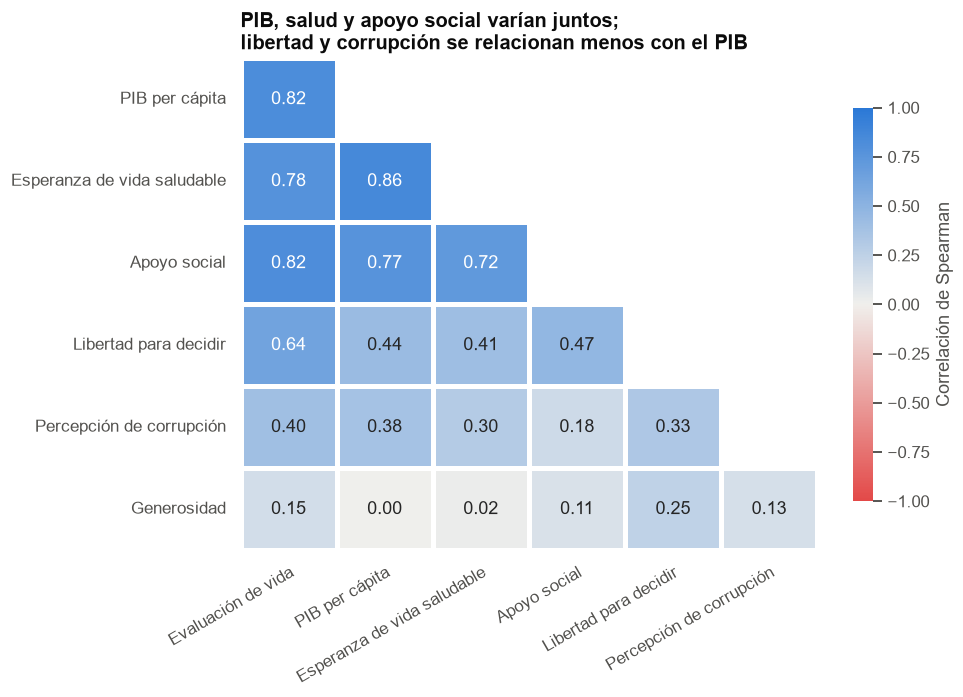

In [14]:
variables = ["evaluacion_vida"] + COMPONENTES
correlacion = df_comp[variables].corr(method="spearman")
correlacion.index = correlacion.columns = [ETIQUETAS[v] for v in variables]
# Solo el triángulo inferior, sin la fila y la columna que quedarían vacías
correlacion = correlacion.iloc[1:, :-1]
mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)
divergente = LinearSegmentedColormap.from_list("rojo_gris_azul", ["#e34948", "#f0efec", "#2a78d6"])

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(correlacion, mask=mascara, cmap=divergente, vmin=-1, vmax=1, annot=True, fmt=".2f",
            linewidths=2, linecolor="white", cbar_kws={"label": "Correlación de Spearman", "shrink": 0.8},
            ax=ax)
ax.grid(False)
ax.set_title("PIB, salud y apoyo social varían juntos;\nlibertad y corrupción se relacionan menos con el PIB", loc="left")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "g4_correlaciones.png", dpi=150)
plt.show()

**Interpretación.**

- La evaluación de vida se correlaciona fuertemente con **PIB (0,82), apoyo social (0,82) y salud (0,78)**, moderadamente con **libertad (0,64)** y débilmente con **corrupción (0,40)** y **generosidad (0,15)**.
- PIB, salud y apoyo social **varían juntos** (entre 0,72 y 0,86): los países con más PIB suelen tener también más salud y más apoyo social. Por eso las brechas de esos tres componentes en el gráfico 3 no son independientes y no pueden leerse como "efectos" separados.
- **Libertad y corrupción** se relacionan menos con el PIB (0,44 y 0,38): aportan información que el PIB no resume. Para la audiencia, son las dimensiones que más vale la pena monitorear por separado.

Estas correlaciones describen asociaciones entre países; no indican qué componente produce cambios en otro.

## 7. Visualizaciones interactivas (Plotly)

### Gráfico 5. Dimensión económica frente a dimensión socioinstitucional
**Qué necesita examinar el analista:** qué países se apartan del patrón de su grupo; por ejemplo, países con una contribución del PIB parecida que están en cuartiles distintos.
**Interacción con propósito analítico:**
- **Pasar el cursor** sobre un punto muestra el país, su evaluación de vida y sus seis contribuciones.
- **Clic en la leyenda** oculta o muestra cuartiles; doble clic aísla uno (por ejemplo, solo Q1 y Q4).
- **El menú desplegable** cambia el eje vertical entre la suma socioinstitucional y cada uno de sus tres componentes.
- **Zoom** con selección de recuadro para separar países superpuestos.

In [15]:
OPCIONES_Y = ["socioinstitucional", "apoyo_social", "libertad", "corrupcion"]
DATOS_HOVER = ["pais", "evaluacion_vida", "pib", "salud", "apoyo_social", "libertad", "corrupcion", "generosidad"]
plantilla_hover = (
    "<b>%{customdata[0]}</b> (%{fullData.name})<br>"
    "Evaluación de vida: %{customdata[1]:.2f}<br>"
    "PIB: %{customdata[2]:.2f} · Salud: %{customdata[3]:.2f}<br>"
    "Apoyo social: %{customdata[4]:.2f} · Libertad: %{customdata[5]:.2f}<br>"
    "Corrupción: %{customdata[6]:.2f} · Generosidad: %{customdata[7]:.2f}<extra></extra>"
)

fig5 = go.Figure()
for q in CUARTILES:   # una traza por cuartil para poder ocultarlos desde la leyenda
    d = df_comp[df_comp["cuartil"] == q]
    fig5.add_trace(go.Scatter(
        x=d["pib"], y=d["socioinstitucional"], mode="markers", name=q,
        marker=dict(size=11, color=COLORES_CUARTIL[q], line=dict(width=1.5, color="white")),
        customdata=d[DATOS_HOVER].to_numpy(), hovertemplate=plantilla_hover,
    ))

# Menú: cambia la variable del eje vertical en las cuatro trazas a la vez
botones = []
for col in OPCIONES_Y:
    botones.append(dict(
        label=ETIQUETAS[col], method="update",
        args=[{"y": [df_comp.loc[df_comp["cuartil"] == q, col] for q in CUARTILES]},
              {"yaxis.title.text": f"{ETIQUETAS[col]} (puntos)"}],
    ))

fig5.update_layout(
    template="simple_white", height=600,
    title=dict(text="Con una contribución del PIB similar, hay países en cuartiles distintos "
                    "y con niveles socioinstitucionales distintos", font=dict(size=15)),
    xaxis_title="PIB per cápita: contribución asociada (puntos de la escalera)",
    yaxis_title=f"{ETIQUETAS['socioinstitucional']} (puntos)",
    legend=dict(title="Cuartil (clic para ocultar)"),
    updatemenus=[dict(buttons=botones, direction="down", x=0, xanchor="left", y=1.12, yanchor="top",
                      showactive=True)],
    margin=dict(t=120),
    hoverlabel=dict(bgcolor="white", font_size=12),
)
fig5.update_xaxes(showgrid=True, gridcolor="#e1e0d9")
fig5.update_yaxes(showgrid=True, gridcolor="#e1e0d9")
fig5.show()

In [16]:
# Apoyo para la lectura del gráfico 5: países que se apartan de su grupo.
# Para cada país se compara su componente socioinstitucional con el esperado según su PIB
# (recta ajustada); el residuo indica cuánto se aparta del patrón general.
# Venezuela se excluye: su contribución del PIB es 0 en el archivo, por lo que su desvío no es interpretable.
validos = df_comp[df_comp["pib"] > 0].copy()
pendiente, intercepto = np.polyfit(validos["pib"], validos["socioinstitucional"], 1)
validos["desvio_socioinst"] = validos["socioinstitucional"] - (intercepto + pendiente * validos["pib"])
cols = ["pais", "cuartil", "evaluacion_vida", "pib", "socioinstitucional", "desvio_socioinst"]
print("Mayor componente socioinstitucional del esperado según su PIB:")
print(validos.nlargest(6, "desvio_socioinst")[cols].round(2).to_string(index=False))
print("\nMenor componente socioinstitucional del esperado según su PIB:")
print(validos.nsmallest(6, "desvio_socioinst")[cols].round(2).to_string(index=False))

Mayor componente socioinstitucional del esperado según su PIB:
      pais cuartil  evaluacion_vida  pib  socioinstitucional  desvio_socioinst
Kyrgyzstan      Q2             5.71 1.05                2.34              0.74
Uzbekistan      Q3             6.20 1.21                2.44              0.70
Mozambique      Q2             5.22 0.56                1.81              0.67
 Nicaragua      Q3             6.28 1.10                2.31              0.67
   Finland      Q4             7.74 1.84                2.98              0.64
     Yemen      Q1             3.56 0.67                1.76              0.52

Menor componente socioinstitucional del esperado según su PIB:
       pais cuartil  evaluacion_vida  pib  socioinstitucional  desvio_socioinst
    Lebanon      Q1             2.71 1.38                0.78             -1.12
Afghanistan      Q1             1.72 0.63                0.09             -1.11
    Comoros      Q1             3.57 0.90                0.66             -0.79


**Interpretación.** La nube muestra una relación positiva entre la dimensión económica y la socioinstitucional, con Q4 concentrado arriba a la derecha y Q1 abajo a la izquierda. Pero hay países que se apartan del patrón (tabla anterior; la recta excluye a Venezuela, cuya contribución del PIB es 0 en el archivo):

- **Más socioinstitucional del esperado según su PIB:** Kirguistán (Q2), Uzbekistán (Q3), Nicaragua (Q3) y Mozambique (Q2) tienen contribuciones del PIB similares a las de Q1, pero están en cuartiles más altos.
- **Menos socioinstitucional del esperado:** Líbano (Q1) y Turquía (Q2) tienen contribuciones del PIB propias de Q3 o Q4 (1,38 y 1,70), pero están en cuartiles bajos y con valores socioinstitucionales bajos.

En el menú, al cambiar a **Percepción de corrupción**, se ve que la mayoría de los países está por debajo de 0,2 sin importar su PIB y que solo un grupo de Q4 se separa, lo que coincide con el gráfico 2. Estos países son candidatos a estudios de caso para la unidad de análisis; el gráfico no explica por qué se apartan.

### Gráfico 6. Composición de la evaluación de vida por país
**Qué necesita examinar el analista:** de qué se compone la evaluación de vida de un país concreto y cómo se compara con los demás de su cuartil. Complementa al gráfico 5: aquel sirve para **encontrar** países atípicos y este para **descomponer** su evaluación.
**Interacción con propósito analítico:**
- **El menú desplegable** muestra un cuartil a la vez (36 países legibles en lugar de 140).
- **Pasar el cursor** muestra el valor de cada componente.
- **Clic en la leyenda** oculta componentes para comparar solo los que interesan (por ejemplo, solo los socioinstitucionales).
- **El punto negro con barra** marca la evaluación de vida y su intervalo de confianza al 95 %: si los intervalos de dos países se superponen, la diferencia de ranking entre ellos no es clara.

In [17]:
PARTES = COMPONENTES + ["distopia_residual"]
inicial = "Q1"
fig6 = go.Figure()
paises_por_cuartil = {}

for q in CUARTILES:
    d = df_comp[df_comp["cuartil"] == q].sort_values("evaluacion_vida")   # el más alto queda arriba
    paises_por_cuartil[q] = d["pais"].tolist()
    for parte in PARTES:
        fig6.add_trace(go.Bar(
            y=d["pais"], x=d[parte], orientation="h", name=ETIQUETAS[parte], legendgroup=parte,
            marker=dict(color=COLORES_DIM[parte], line=dict(width=1, color="white")),
            visible=(q == inicial),
            hovertemplate="<b>%{y}</b><br>" + ETIQUETAS[parte] + ": %{x:.2f}<extra></extra>",
        ))
    # Evaluación de vida con su intervalo de confianza al 95 %
    fig6.add_trace(go.Scatter(
        y=d["pais"], x=d["evaluacion_vida"], mode="markers", name="Evaluación de vida (IC 95 %)",
        legendgroup="ic", marker=dict(color="#0b0b0b", size=7),
        error_x=dict(type="data", symmetric=False, array=d["ic_superior"] - d["evaluacion_vida"],
                     arrayminus=d["evaluacion_vida"] - d["ic_inferior"], color="#0b0b0b", thickness=1.5),
        visible=(q == inicial),
        hovertemplate="<b>%{y}</b><br>Evaluación de vida: %{x:.2f}<extra></extra>",
    ))

trazas_por_cuartil = len(PARTES) + 1
botones = []
for i, q in enumerate(CUARTILES):
    visibles = [i * trazas_por_cuartil <= j < (i + 1) * trazas_por_cuartil for j in range(len(fig6.data))]
    botones.append(dict(
        label=f"{q} ({len(paises_por_cuartil[q])} países)", method="update",
        args=[{"visible": visibles},
              {"yaxis.categoryarray": paises_por_cuartil[q],
               "yaxis.range": [-0.5, len(paises_por_cuartil[q]) - 0.5]}],
    ))

fig6.update_layout(
    template="simple_white", barmode="relative", bargap=0.25, height=950,
    title=dict(text="Composición de la evaluación de vida por país (elija el cuartil en el menú)", font=dict(size=15)),
    xaxis_title="Puntos de la escalera de Cantril (la suma de las barras es la evaluación de vida)",
    yaxis=dict(categoryorder="array", categoryarray=paises_por_cuartil[inicial],
               range=[-0.5, len(paises_por_cuartil[inicial]) - 0.5], tickfont=dict(size=11)),
    legend=dict(orientation="h", y=-0.07, x=0, yanchor="top", traceorder="normal"),
    updatemenus=[dict(buttons=botones, direction="down", x=1, xanchor="right", y=1.02, yanchor="bottom",
                      active=CUARTILES.index(inicial))],
    margin=dict(t=90, b=130, l=160),
    hoverlabel=dict(bgcolor="white", font_size=12),
)
fig6.update_xaxes(showgrid=True, gridcolor="#e1e0d9", zeroline=True, zerolinecolor="#c3c2b7")
fig6.show()

**Interpretación.** Al recorrer los cuartiles con el menú:

- En **Q1**, la composición es muy diversa. **Líbano** y **Botsuana** tienen contribuciones del PIB altas, pero el Líbano tiene contribuciones muy bajas en libertad (0,17) y corrupción (0,03) y un residual negativo (−0,07). **Afganistán** tiene contribución 0 en apoyo social y libertad.
- En varios países de Q1 (por ejemplo, Níger, Burkina Faso o Chad), **Distopía + residual** es una de las barras más largas: su evaluación de vida es mayor de lo que el modelo asocia con sus seis indicadores.
- En **Q4**, las barras de PIB y apoyo social son largas y parejas entre países; las diferencias dentro del grupo aparecen sobre todo en corrupción.
- Los **intervalos de confianza** de países vecinos se superponen con frecuencia, en especial en Q2 y Q3: pequeñas diferencias de posición en el ranking no son diferencias claras.

Para la audiencia, este gráfico muestra que dos países con la misma evaluación de vida pueden llegar a ella con composiciones muy distintas, y que un diagnóstico de país debería revisar la composición y no solo el puntaje.

In [18]:
# 7.1 Exportación de las visualizaciones interactivas a un archivo HTML autocontenido
ruta_html = RUTA_RESULTADOS / "Proyecto2_visualizaciones_interactivas.html"
with open(ruta_html, "w", encoding="utf-8") as f:
    f.write("<html><head><meta charset='utf-8'><title>Proyecto 2 - Visualizaciones interactivas</title></head><body>")
    f.write(fig5.to_html(full_html=False, include_plotlyjs=True))
    f.write(fig6.to_html(full_html=False, include_plotlyjs=False))
    f.write("</body></html>")
print(f"HTML guardado en {ruta_html}")

HTML guardado en resultados\Proyecto2_visualizaciones_interactivas.html


## 8. Conclusiones, limitaciones y nuevas preguntas

### Respuesta a la pregunta analítica
**¿En qué dimensiones se observan las mayores diferencias entre los países con mayor y menor evaluación de vida en el WHR 2024?**

1. **El PIB per cápita es el componente individual con mayor brecha** entre Q4 y Q1 (0,90 de 2,96 puntos; 30 %), seguido muy de cerca por el **apoyo social** (0,67; 22 %). Ambos aumentan de forma gradual de Q1 a Q4 (gráficos 2 y 3).
2. **La dimensión socioinstitucional en conjunto supera a la económica**: apoyo social, libertad y corrupción suman 1,09 puntos (37 %). La **salud** aporta 0,32 y la **generosidad** no diferencia a los grupos.
3. **La percepción de corrupción distingue solo al grupo más alto**: es similar en Q1, Q2 y Q3 y solo sube en Q4 (gráfico 2).
4. **Las dimensiones no son independientes**: PIB, salud y apoyo social varían juntos, mientras que libertad y corrupción aportan información menos ligada al PIB (gráfico 4).
5. **Hay países que se apartan del patrón**: con una contribución del PIB similar, Kirguistán, Uzbekistán o Nicaragua tienen niveles socioinstitucionales altos y están en cuartiles medios, mientras que Líbano y Turquía tienen niveles bajos y están en cuartiles bajos (gráficos 5 y 6).

**Implicación para la audiencia:** un diagnóstico de país centrado solo en indicadores económicos dejaría fuera una parte de la brecha de bienestar de magnitud comparable o mayor. Apoyo social, libertad y percepción de corrupción merecen seguimiento propio, en especial libertad y corrupción, que son las menos redundantes con el PIB.

### Limitaciones
- **No hay causalidad.** Las contribuciones son asociaciones estimadas por el modelo del WHR; no indican qué pasaría con la evaluación de vida si un indicador cambiara.
- **Las contribuciones dependen del modelo.** Cada contribución es el indicador del país multiplicado por un coeficiente común, en relación con Distopía. La comparación entre dimensiones refleja también esos pesos, no solo las diferencias en los indicadores.
- **Una parte de la brecha no se explica** (Distopía + residual, 22 %).
- **Datos agregados por país** (promedio 2021–2023): no muestran desigualdades dentro de los países ni cambios en el tiempo.
- **Casos especiales:** tres países sin contribuciones (Bahrain, Tajikistan, State of Palestine), Venezuela con contribución del PIB igual a 0 y Líbano con residual negativo.
- **Los cuartiles son una elección del equipo:** permiten grupos de tamaño similar, pero los cortes son convencionales y Q1 es muy heterogéneo.

### Nuevas preguntas de investigación
- ¿Se mantiene el patrón al usar los valores originales de los indicadores (por ejemplo, el porcentaje de personas con apoyo social) en lugar de las contribuciones del modelo?
- ¿Qué características comparten los países que se apartan del patrón (Kirguistán, Uzbekistán, Nicaragua frente a Líbano o Turquía)?
- ¿Cambian las brechas entre grupos de edad dentro de los países? (Requiere los datos por edad del WHR 2024, que no están en el archivo de la Figura 2.1.)
- ¿Cómo han evolucionado estas brechas en el tiempo?

In [19]:
# Comprobación de reproducibilidad: archivos generados por este Notebook
for archivo in sorted(RUTA_RESULTADOS.iterdir()):
    print(f"{archivo.name:50s} {archivo.stat().st_size / 1024:8.1f} KB")

g1_distribucion.png                                    70.0 KB
g2_boxplots.png                                        78.6 KB
g3_brechas.png                                         66.7 KB
g4_correlaciones.png                                  120.5 KB
Proyecto2_visualizaciones_interactivas.html          4805.5 KB
whr24_preparado.csv                                    30.4 KB
